In [1]:
!pip install optuna

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import optuna

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = (device.type == "cuda")

print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. Training will use CPU.")

Using device: cuda
GPU: Tesla T4


In [3]:
# Load the rainfall dataset
df = pd.read_csv("Yemen_Rainfall_1982_2025.csv")
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (503712, 19)


,Unnamed: 0,date,adm_level,adm_id,PCODE,n_pixels,rfh,rfh_avg,r1h,r1h_avg,r3h,r3h_avg,rfq,r1q,r3q,version,month,dekad,year
0,454320,1982-01-01,2,32878,0,24.0,1.000000,1.043055,4.000000,3.880556,9.833333,14.137500,99.28752,101.34500,77.509250,final,1,1,1982
1,478770,1982-01-01,2,32893,1,19.0,1.157895,1.049123,4.157895,4.145614,9.263158,13.300000,101.79814,100.13426,77.940760,final,1,1,1982
2,455950,1982-01-01,2,32879,2,10.0,1.000000,1.023333,4.000000,4.253334,9.400000,12.836667,99.61261,97.26224,80.732574,final,1,1,1982
3,457580,1982-01-01,2,32880,3,9.0,1.000000,1.003704,4.000000,4.166666,9.888889,13.162963,99.93831,98.18182,81.973900,final,1,1,1982
4,464100,1982-01-01,2,32884,4,6.0,1.000000,1.055556,4.000000,4.094444,10.000000,13.688889,99.08257,98.96152,80.261600,final,1,1,1982


In [4]:
# Clean unused columns and construct a reliable timestamp from the dataset's
# year/month/dekad fields. This avoids depending on a missing or inconsistent
# pre-existing date column.
drop_cols = [
    'rfq', 'r1q', 'r3q', 'rfh_avg', 'r1h_avg', 'r3h_avg',
    'n_pixels', 'version', 'Unnamed: 0', 'adm_id', 'adm_level'
]
df = df.drop(columns=drop_cols, errors='ignore').copy()

required_cols = ['PCODE', 'year', 'month', 'dekad', 'rfh', 'r1h', 'r3h']
missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Dataset is missing required columns: {missing_cols}")

for col in ['year', 'month', 'dekad', 'rfh', 'r1h', 'r3h']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df['PCODE'] = df['PCODE'].astype('string').str.strip()
df = df.dropna(subset=required_cols).copy()

# Yemen rainfall data uses dekad values 1, 2, 3 (three periods per month).
# Convert them to representative dates: day 1, 11, and 21.
dekad_values = set(df['dekad'].astype(int).unique())
if dekad_values.issubset({1, 2, 3}):
    day = (df['dekad'].astype(int) - 1) * 10 + 1
else:
    # If dekad is already represented as a day-of-month, use it directly.
    day = df['dekad'].clip(1, 28).astype(int)

df['date'] = pd.to_datetime(
    dict(
        year=df['year'].astype(int),
        month=df['month'].astype(int),
        day=day.astype(int)
    ),
    errors='coerce'
)

df = df.dropna(subset=['date'])
df = df.sort_values(['PCODE', 'date']).reset_index(drop=True)

print("After cleaning:", df.shape)
print("Date range:", df['date'].min(), "to", df['date'].max())
print("Unique regions:", df['PCODE'].nunique())
print("Year range:", int(df['year'].min()), "to", int(df['year'].max()))

After cleaning: (503712, 8)
Date range: 1982-01-01 00:00:00 to 2025-12-21 00:00:00
Unique regions: 318
Year range: 1982 to 2025


In [5]:
# Create lagged rainfall features independently for each administrative region.
LAGS = [1, 2, 3, 6, 12]

def create_lags(data):
    data = data.sort_values(['PCODE', 'date']).copy()
    for lag in LAGS:
        data[f'rfh_lag_{lag}'] = data.groupby('PCODE')['rfh'].shift(lag)
    return data

df = create_lags(df)

# Drop only rows that cannot form all lag features.
df = df.dropna(subset=[f'rfh_lag_{lag}' for lag in LAGS]).reset_index(drop=True)
print("Shape after lag creation:", df.shape)

Shape after lag creation: (499896, 13)


In [6]:
# Encode region identifiers as consecutive integers for nn.Embedding.
pcode_categories = pd.Index(df['PCODE'].astype(str).unique())
pcode_to_id = {code: idx for idx, code in enumerate(pcode_categories)}
df['PCODE'] = df['PCODE'].astype(str).map(pcode_to_id).astype('int64')

num_pcodes = len(pcode_to_id)
print("Number of unique PCodes:", num_pcodes)

Number of unique PCodes: 318


In [7]:
# Cyclical calendar encoding
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
df['dekad_sin'] = np.sin(2 * np.pi * df['dekad'] / 3)
df['dekad_cos'] = np.cos(2 * np.pi * df['dekad'] / 3)

display(df.head())


,date,PCODE,rfh,r1h,r3h,month,dekad,year,rfh_lag_1,rfh_lag_2,rfh_lag_3,rfh_lag_6,rfh_lag_12,month_sin,month_cos,dekad_sin,dekad_cos
0,1982-05-01,0,11.666667,19.708334,37.625000,5,1,1982,3.333333,4.708334,4.041666,1.000000,1.000000,5.000000e-01,-0.866025,8.660254e-01,-0.5
1,1982-05-11,0,14.416667,29.416668,48.458336,5,11,1982,11.666667,3.333333,4.708334,0.291667,3.000000,5.000000e-01,-0.866025,-8.660254e-01,-0.5
2,1982-05-21,0,7.125000,33.208336,54.583336,5,21,1982,14.416667,11.666667,3.333333,8.000000,1.000000,5.000000e-01,-0.866025,-1.714506e-15,1.0
3,1982-06-01,0,1.333333,22.875002,54.916668,6,1,1982,7.125000,14.416667,11.666667,4.041666,1.000000,1.224647e-16,-1.000000,8.660254e-01,-0.5
4,1982-06-11,0,0.000000,8.458333,54.625000,6,11,1982,1.333333,7.125000,14.416667,4.708334,3.583333,1.224647e-16,-1.000000,-8.660254e-01,-0.5


In [8]:

num_features = [
    'rfh', 'r1h', 'r3h',
    'month_sin', 'month_cos',
    'dekad_sin', 'dekad_cos',
    'rfh_lag_1', 'rfh_lag_2', 'rfh_lag_3',
    'rfh_lag_6', 'rfh_lag_12'
]

cat_feature = 'PCODE'

TRAIN_END = pd.Timestamp('2015-12-31')
VAL_END = pd.Timestamp('2020-12-31')
WINDOW = 36

# ---------------------------------------
# 1. Identify rainfall columns
# ---------------------------------------

log_features = [
    'rfh', 'r1h', 'r3h',
    'rfh_lag_1', 'rfh_lag_2', 'rfh_lag_3',
    'rfh_lag_6', 'rfh_lag_12'
]

# ---------------------------------------
# 2. Training-period selection
# ---------------------------------------

train_rows = df['date'] <= TRAIN_END

if not train_rows.any():
    raise ValueError(
        "No training rows found through 2015. "
        "Check the dataset year/date columns."
    )

# ---------------------------------------
# 3. Apply Log Transformation
# ---------------------------------------

df_model = df.copy()

# Rainfall values must be non-negative for log1p.
for col in log_features:
    if (df_model[col] < 0).any():
        raise ValueError(
            f"Negative rainfall values found in {col}. "
            "Check the dataset before applying log1p."
        )

df_model.loc[:, log_features] = np.log1p(
    df_model[log_features]
)

# ---------------------------------------
# 4. Apply Min-Max Scaling
# ---------------------------------------

scaler = MinMaxScaler()

# Fit only on training-period observations.
scaler.fit(
    df_model.loc[train_rows, num_features]
)

# Transform all observations using training scaler.
df_model.loc[:, num_features] = scaler.transform(
    df_model[num_features]
)

# ---------------------------------------
# 5. Model configuration
# ---------------------------------------

rfh_feature_index = num_features.index('rfh')

num_pcodes = int(
    df_model[cat_feature].nunique()
)

# ---------------------------------------
# 6. Display dataset information
# ---------------------------------------

print("Log Transformation: Applied")
print("Min-Max Scaling: Applied")

print("\nLog-transformed columns:")
print(log_features)

print("\nMin-Max scaled columns:")
print(num_features)

print("\nTraining rows:", int(train_rows.sum()))

print(
    "Validation rows:",
    int(((df['date'] > TRAIN_END) &
         (df['date'] <= VAL_END)).sum())
)

print(
    "Test rows:",
    int((df['date'] > VAL_END).sum())
)

print("Number of PCODE categories:", num_pcodes)

print(
    "\nValidation target period:",
    TRAIN_END + pd.Timedelta(days=1),
    "to", VAL_END
)

print(
    "Test target period:",
    VAL_END + pd.Timedelta(days=1),
    "onward"
)


Log Transformation: Applied
Min-Max Scaling: Applied

Log-transformed columns:
['rfh', 'r1h', 'r3h', 'rfh_lag_1', 'rfh_lag_2', 'rfh_lag_3', 'rfh_lag_6', 'rfh_lag_12']

Min-Max scaled columns:
['rfh', 'r1h', 'r3h', 'month_sin', 'month_cos', 'dekad_sin', 'dekad_cos', 'rfh_lag_1', 'rfh_lag_2', 'rfh_lag_3', 'rfh_lag_6', 'rfh_lag_12']

Training rows: 385416
Validation rows: 57240
Test rows: 57240
Number of PCODE categories: 318

Validation target period: 2016-01-01 00:00:00 to 2020-12-31 00:00:00
Test target period: 2021-01-01 00:00:00 onward


In [9]:
def create_sequences(
    data,
    num_features,
    cat_feature,
    window=36,
    target_start=None,
    target_end=None
):
    """
    Build sequences separately for each region.

    The target date determines whether a sample belongs to train/validation/test.
    Validation and test samples may use earlier observations as historical context.
    """
    X_num, X_cat, y, target_dates = [], [], [], []

    start = pd.Timestamp(target_start) if target_start is not None else None
    end = pd.Timestamp(target_end) if target_end is not None else None

    data = data.sort_values([cat_feature, 'date']).copy()

    for pcode, region in data.groupby(cat_feature, sort=False):
        region = region.sort_values('date').reset_index(drop=True)

        num_data = region[num_features].to_numpy(dtype=np.float32)
        cat_data = region[cat_feature].to_numpy(dtype=np.int64)
        dates = pd.to_datetime(region['date']).to_numpy()

        if len(region) <= window:
            continue

        for i in range(window, len(region)):
            target_date = pd.Timestamp(dates[i])

            if start is not None and target_date < start:
                continue
            if end is not None and target_date > end:
                continue

            X_num.append(num_data[i-window:i])
            X_cat.append(cat_data[i-window:i])
            y.append(num_data[i, num_features.index('rfh')])
            target_dates.append(target_date)

    if len(X_num) == 0:
        return (
            np.empty((0, window, len(num_features)), dtype=np.float32),
            np.empty((0, window), dtype=np.int64),
            np.empty((0,), dtype=np.float32),
            np.empty((0,), dtype='datetime64[ns]')
        )

    return (
        np.asarray(X_num, dtype=np.float32),
        np.asarray(X_cat, dtype=np.int64),
        np.asarray(y, dtype=np.float32),
        np.asarray(target_dates, dtype='datetime64[ns]')
    )

In [10]:
# Generate splits from the complete timeline so that validation/test sequences
# can use the previous WINDOW observations as context.
X_train_num, X_train_cat, y_train, train_dates = create_sequences(
    df_model, num_features, cat_feature,
    window=WINDOW, target_start=None, target_end=TRAIN_END
)

X_val_num, X_val_cat, y_val, val_dates = create_sequences(
    df_model, num_features, cat_feature,
    window=WINDOW,
    target_start=TRAIN_END + pd.Timedelta(days=1),
    target_end=VAL_END
)

X_test_num, X_test_cat, y_test, test_dates = create_sequences(
    df_model, num_features, cat_feature,
    window=WINDOW,
    target_start=VAL_END + pd.Timedelta(days=1),
    target_end=None
)

def check_split(name, X_num, X_cat, y, dates):
    print(
        f"{name}: X_num={X_num.shape}, X_cat={X_cat.shape}, "
        f"y={y.shape}, date_count={len(dates)}"
    )
    if len(y) == 0:
        raise ValueError(
            f"{name} split is empty. Dataset dates: "
            f"{df_model['date'].min()} to {df_model['date'].max()}. "
            f"Check whether it contains observations in the requested period "
            f"and at least {WINDOW + 1} observations per region."
        )

check_split("Train", X_train_num, X_train_cat, y_train, train_dates)
check_split("Validation", X_val_num, X_val_cat, y_val, val_dates)
check_split("Test", X_test_num, X_test_cat, y_test, test_dates)

Train: X_num=(373968, 36, 12), X_cat=(373968, 36), y=(373968,), date_count=373968
Validation: X_num=(57240, 36, 12), X_cat=(57240, 36), y=(57240,), date_count=57240
Test: X_num=(57240, 36, 12), X_cat=(57240, 36), y=(57240,), date_count=57240


In [11]:
print("Train numerical:", X_train_num.shape)
print("Train categorical:", X_train_cat.shape)
print("Train target:", y_train.shape)

print("Validation numerical:", X_val_num.shape)
print("Validation categorical:", X_val_cat.shape)
print("Validation target:", y_val.shape)

print("Test numerical:", X_test_num.shape)
print("Test categorical:", X_test_cat.shape)
print("Test target:", y_test.shape)

Train numerical: (373968, 36, 12)
Train categorical: (373968, 36)
Train target: (373968,)
Validation numerical: (57240, 36, 12)
Validation categorical: (57240, 36)
Validation target: (57240,)
Test numerical: (57240, 36, 12)
Test categorical: (57240, 36)
Test target: (57240,)


In [12]:
class GRUModel(nn.Module):
    def __init__(
        self,
        num_features,
        num_pcodes,
        embed_dim,
        hidden_size,
        num_layers,
        dropout
    ):
        super().__init__()

        # PCODE embedding
        self.embedding = nn.Embedding(
            num_pcodes,
            embed_dim
        )

        # GRU
        self.gru = nn.GRU(
            input_size=num_features + embed_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        # Output layer
        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x_num, x_cat):

        # PCODE embedding
        x_cat = self.embedding(x_cat)

        # Concatenate numerical features + PCODE embedding
        x = torch.cat(
            [x_num, x_cat],
            dim=-1
        )

        # GRU
        out, _ = self.gru(x)

        # Last time step
        out = out[:, -1, :]

        # Prediction
        return self.fc(out).squeeze(-1)

In [13]:
def objective(trial):
    hidden_size = trial.suggest_int("hidden_size", 64, 128)
    num_layers = trial.suggest_int("num_layers", 1, 3)
    dropout = trial.suggest_float("dropout", 0.0, 0.3)
    lr = trial.suggest_float("lr", 1e-4, 5e-3, log=True)
    batch_size = trial.suggest_categorical("batch_size", [64, 128])
    embed_dim = trial.suggest_int("embed_dim", 4, 16)

    train_loader = to_loader(
        X_train_num, X_train_cat, y_train, batch_size, shuffle=True
    )
    val_loader = to_loader(
        X_val_num, X_val_cat, y_val, batch_size, shuffle=False
    )

    model = GRUModel(
        num_features=X_train_num.shape[2],
        num_pcodes=num_pcodes,
        embed_dim=embed_dim,
        hidden_size=hidden_size,
        num_layers=num_layers,
        dropout=dropout
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    max_epochs = 30
    patience = 6
    best_val_loss = float("inf")
    epochs_without_improvement = 0

    for epoch in range(max_epochs):
        model.train()
        for xb_num, xb_cat, yb in train_loader:
            xb_num = xb_num.to(device, non_blocking=True)
            xb_cat = xb_cat.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            pred = model(xb_num, xb_cat)
            loss = loss_fn(pred, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        model.eval()
        val_losses = []
        with torch.no_grad():
            for xb_num, xb_cat, yb in val_loader:
                xb_num = xb_num.to(device, non_blocking=True)
                xb_cat = xb_cat.to(device, non_blocking=True)
                yb = yb.to(device, non_blocking=True)
                val_losses.append(loss_fn(model(xb_num, xb_cat), yb).item())

        val_loss = float(np.mean(val_losses))
        trial.report(val_loss, epoch)

        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()

    return best_val_loss

In [14]:
# DataLoader utility: pinned memory speeds CPU-to-GPU transfer when CUDA is used.
def to_loader(X_num, X_cat, y, batch_size=64, shuffle=False):
    if len(y) == 0:
        raise ValueError("Cannot create a DataLoader from an empty split.")

    dataset = TensorDataset(
        torch.as_tensor(X_num, dtype=torch.float32),
        torch.as_tensor(X_cat, dtype=torch.long),
        torch.as_tensor(y, dtype=torch.float32)
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        pin_memory=PIN_MEMORY,
        num_workers=0
    )

In [15]:
print("Training numerical data:", X_train_num.shape)
print("Training categorical data:", X_train_cat.shape)
print("Training target:", y_train.shape)

print("Validation numerical data:", X_val_num.shape)
print("Validation categorical data:", X_val_cat.shape)
print("Validation target:", y_val.shape)

Training numerical data: (373968, 36, 12)
Training categorical data: (373968, 36)
Training target: (373968,)
Validation numerical data: (57240, 36, 12)
Validation categorical data: (57240, 36)
Validation target: (57240,)


In [16]:
# Hyperparameter optimization
sampler = optuna.samplers.TPESampler(seed=SEED)
study = optuna.create_study(
    direction="minimize",
    sampler=sampler,
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5)
)

study.optimize(objective, n_trials=20)

print("Best Params:", study.best_params)
print("Best Validation Loss:", study.best_value)

[I 2026-11-13 07:26:36,185] A new study created in memory with name: no-name-09f80c5b-209b-4481-bb11-e315a20402bc
[I 2026-11-13 07:29:52,912] Trial 0 finished with value: 0.0077843467673734245 and parameters: {'hidden_size': 88, 'num_layers': 3, 'dropout': 0.21959818254342153, 'lr': 0.0010401663679887319, 'batch_size': 64, 'embed_dim': 4}. Best is trial 0 with value: 0.0077843467673734245.
[I 2026-11-13 07:33:38,350] Trial 1 finished with value: 0.0070332099021511284 and parameters: {'hidden_size': 120, 'num_layers': 2, 'dropout': 0.21242177333881365, 'lr': 0.00010838581269344756, 'batch_size': 64, 'embed_dim': 6}. Best is trial 1 with value: 0.0070332099021511284.
[I 2026-11-13 07:36:54,529] Trial 2 finished with value: 0.0075343248994979364 and parameters: {'hidden_size': 75, 'num_layers': 1, 'dropout': 0.09127267288786131, 'lr': 0.0007790143126276247, 'batch_size': 64, 'embed_dim': 11}. Best is trial 1 with value: 0.0070332099021511284.
[I 2026-11-13 07:39:53,813] Trial 3 finished w

Best Params: {'hidden_size': 102, 'num_layers': 1, 'dropout': 0.1822634555704315, 'lr': 0.00019485671251272575, 'batch_size': 128, 'embed_dim': 16}
Best Validation Loss: 0.006971614594606633


In [17]:
best = study.best_params

model = GRUModel(
    num_features=X_train_num.shape[2],
    num_pcodes=num_pcodes,
    embed_dim=best["embed_dim"],
    hidden_size=best["hidden_size"],
    num_layers=best["num_layers"],
    dropout=best["dropout"]
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=best["lr"])
loss_fn = nn.MSELoss()

train_loader = to_loader(
    X_train_num, X_train_cat, y_train, best["batch_size"], shuffle=True
)
val_loader = to_loader(
    X_val_num, X_val_cat, y_val, best["batch_size"], shuffle=False
)
test_loader = to_loader(
    X_test_num, X_test_cat, y_test, best["batch_size"], shuffle=False
)

print("Model device:", next(model.parameters()).device)

Model device: cuda:0


In [18]:
# Final training with early stopping.
MAX_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 12
best_val_loss = float("inf")
epochs_without_improvement = 0
history = {"train_loss": [], "val_loss": []}

checkpoint_path = "gru_model.pth"

for epoch in range(MAX_EPOCHS):
    model.train()
    train_losses = []

    for xb_num, xb_cat, yb in train_loader:
        xb_num = xb_num.to(device, non_blocking=True)
        xb_cat = xb_cat.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        pred = model(xb_num, xb_cat)
        loss = loss_fn(pred, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        train_losses.append(loss.item())

    train_loss = float(np.mean(train_losses))

    model.eval()
    val_losses = []
    with torch.no_grad():
        for xb_num, xb_cat, yb in val_loader:
            xb_num = xb_num.to(device, non_blocking=True)
            xb_cat = xb_cat.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            pred = model(xb_num, xb_cat)
            val_losses.append(loss_fn(pred, yb).item())

    val_loss = float(np.mean(val_losses))
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1:03d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(model.state_dict(), checkpoint_path)
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(
            f"Early stopping at epoch {epoch + 1}. "
            f"Best validation loss: {best_val_loss:.6f}"
        )
        break

# Restore the model weights from the best validation epoch.
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()
print("Best validation loss:", best_val_loss)

Epoch 001/50 | Train Loss: 0.012409 | Val Loss: 0.011203
Epoch 002/50 | Train Loss: 0.008168 | Val Loss: 0.008474
Epoch 003/50 | Train Loss: 0.007140 | Val Loss: 0.008533
Epoch 004/50 | Train Loss: 0.006721 | Val Loss: 0.007719
Epoch 005/50 | Train Loss: 0.006429 | Val Loss: 0.007659
Epoch 006/50 | Train Loss: 0.006211 | Val Loss: 0.007671
Epoch 007/50 | Train Loss: 0.006047 | Val Loss: 0.007860
Epoch 008/50 | Train Loss: 0.005905 | Val Loss: 0.007707
Epoch 009/50 | Train Loss: 0.005778 | Val Loss: 0.007360
Epoch 010/50 | Train Loss: 0.005677 | Val Loss: 0.007630
Epoch 011/50 | Train Loss: 0.005582 | Val Loss: 0.007157
Epoch 012/50 | Train Loss: 0.005497 | Val Loss: 0.007447
Epoch 013/50 | Train Loss: 0.005423 | Val Loss: 0.007143
Epoch 014/50 | Train Loss: 0.005351 | Val Loss: 0.007558
Epoch 015/50 | Train Loss: 0.005283 | Val Loss: 0.007511
Epoch 016/50 | Train Loss: 0.005213 | Val Loss: 0.007223
Epoch 017/50 | Train Loss: 0.005161 | Val Loss: 0.007207
Epoch 018/50 | Train Loss: 0.00

In [19]:
# Evaluate once on the held-out test set.
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()

preds_scaled, actuals_scaled = [], []

with torch.no_grad():
    for xb_num, xb_cat, yb in test_loader:
        xb_num = xb_num.to(device, non_blocking=True)
        xb_cat = xb_cat.to(device, non_blocking=True)

        pred = model(xb_num, xb_cat)
        preds_scaled.extend(pred.detach().cpu().numpy().reshape(-1))
        actuals_scaled.extend(yb.detach().cpu().numpy().reshape(-1))

preds_scaled = np.asarray(preds_scaled, dtype=np.float64)
actuals_scaled = np.asarray(actuals_scaled, dtype=np.float64)

# Inverse-transform the scaled rainfall target into original rainfall units.
rfh_min = scaler.data_min_[rfh_feature_index]
rfh_range = scaler.data_range_[rfh_feature_index]
preds = preds_scaled * rfh_range + rfh_min
actuals = actuals_scaled * rfh_range + rfh_min

print("Test predictions:", preds.shape)
print("Test observations:", actuals.shape)

Test predictions: (57240,)
Test observations: (57240,)


In [20]:
# Test-set regression metrics in the original rainfall units.
rmse = np.sqrt(mean_squared_error(actuals, preds))
mae = mean_absolute_error(actuals, preds)
r2 = r2_score(actuals, preds)

print(f"RMSE: {rmse:.6f}")
print(f"MAE : {mae:.6f}")
print(f"R²  : {r2:.6f}")

RMSE: 0.481210
MAE : 0.329055
R²  : 0.751008


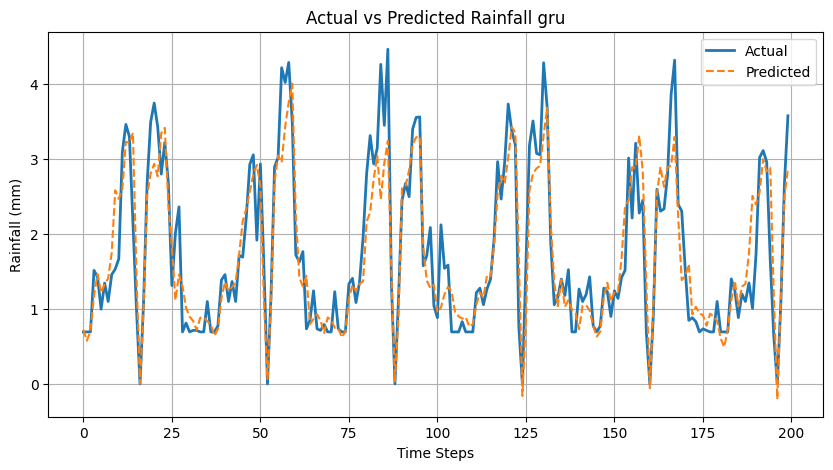

In [21]:
plt.figure(figsize=(10,5))


plt.plot(actuals[:200], label="Actual", linewidth=2)
plt.plot(preds[:200], label="Predicted", linestyle='--')

plt.xlabel("Time Steps")          # X-axis label
plt.ylabel("Rainfall (mm)")       # Y-axis label
plt.title("Actual vs Predicted Rainfall gru")  # Title

plt.legend()
plt.grid(True)

plt.show()

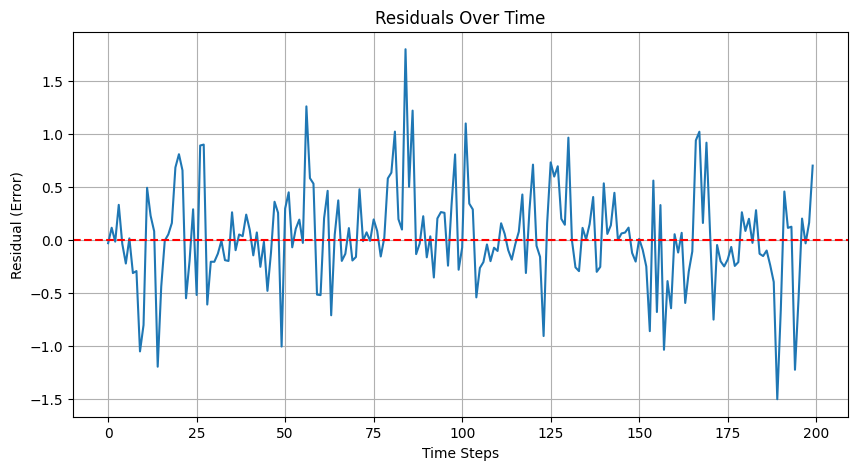

In [22]:
residuals = np.array(actuals) - np.array(preds)

plt.figure(figsize=(10,5))
plt.plot(residuals[:200])

plt.axhline(0, color='r', linestyle='--')  # zero line

plt.xlabel("Time Steps")
plt.ylabel("Residual (Error)")
plt.title("Residuals Over Time")

plt.grid(True)
plt.show()

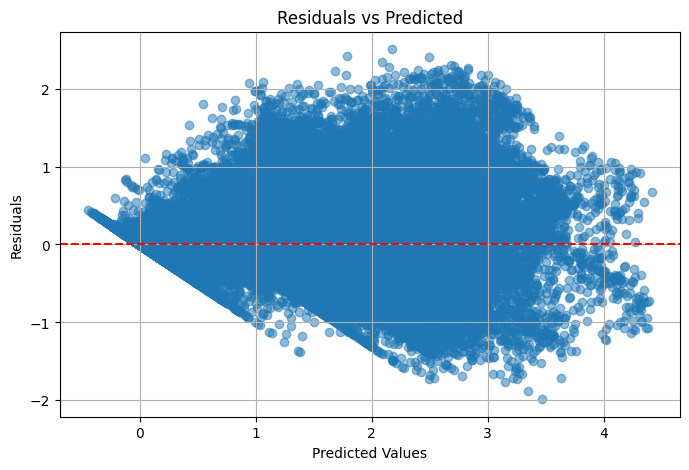

In [23]:
plt.figure(figsize=(8,5))
plt.scatter(preds, residuals, alpha=0.5)

plt.axhline(0, color='r', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted")

plt.grid(True)
plt.show()

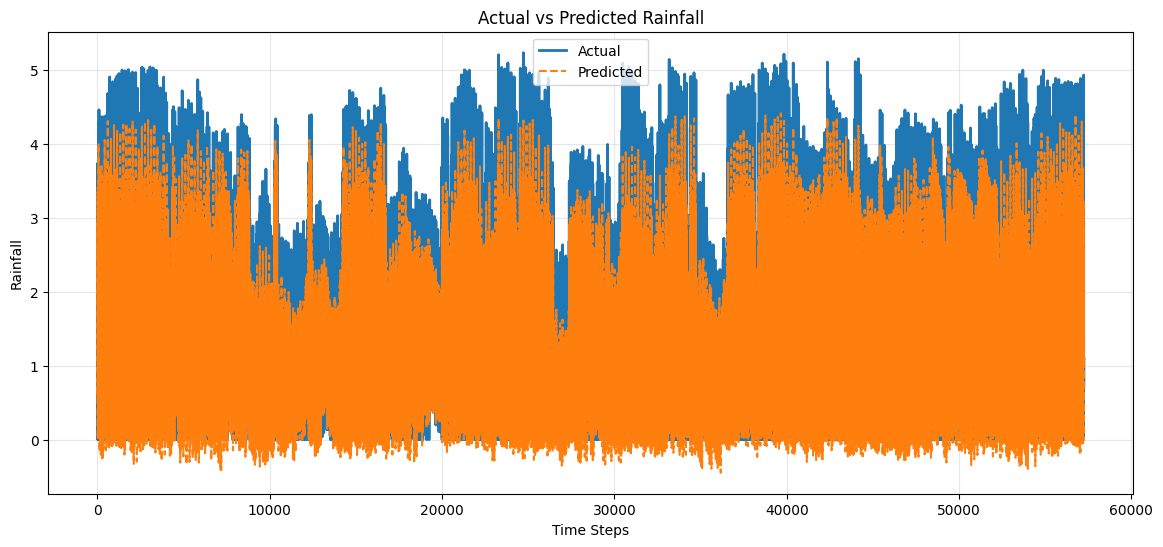

In [24]:
y_true = np.array(actuals).flatten()
y_pred = np.array(preds).flatten()

plt.figure(figsize=(14,6))

plt.plot(y_true, label="Actual", linewidth=2)
plt.plot(y_pred, label="Predicted", linestyle='--')

plt.title("Actual vs Predicted Rainfall")
plt.xlabel("Time Steps")
plt.ylabel("Rainfall")

plt.legend()
plt.grid(alpha=0.3)

plt.savefig("actual_vs_predicted_gru.png", dpi=300)
plt.show()

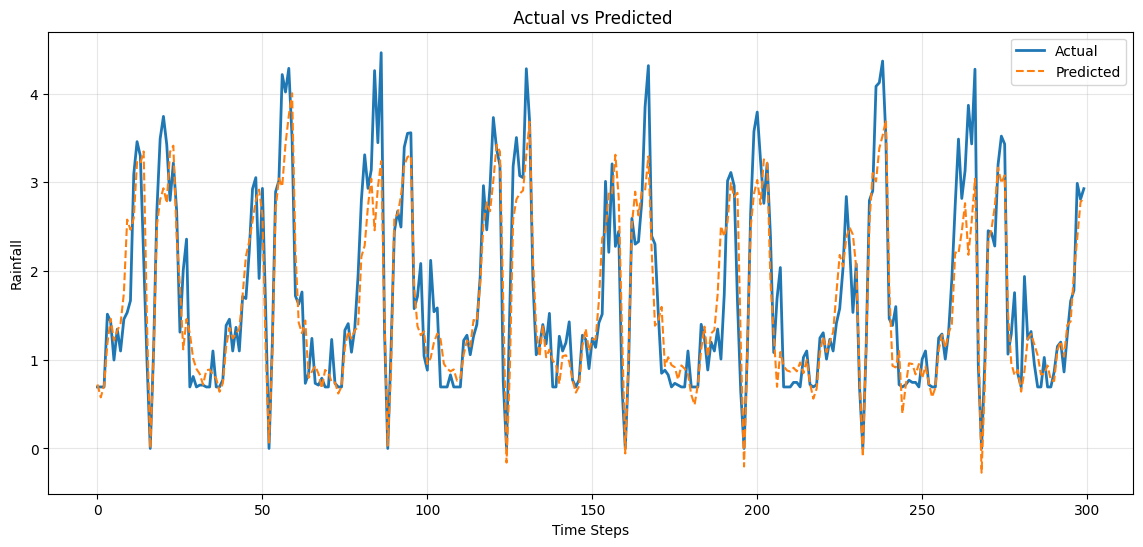

In [25]:
start, end = 0, 300

plt.figure(figsize=(14,6))

plt.plot(y_true[start:end], label="Actual", linewidth=2)
plt.plot(y_pred[start:end], label="Predicted", linestyle='--')

plt.title(" Actual vs Predicted")
plt.xlabel("Time Steps")
plt.ylabel("Rainfall")

plt.legend()
plt.grid(alpha=0.3)

plt.savefig("zoom_plot_gru.png", dpi=300)
plt.show()

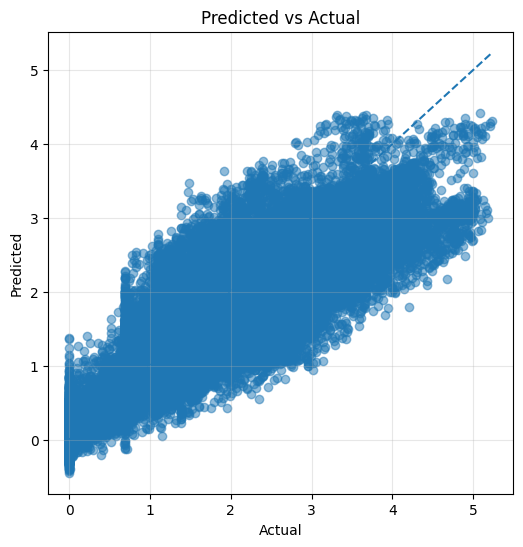

In [26]:
plt.figure(figsize=(6,6))

plt.scatter(y_true, y_pred, alpha=0.5)

# perfect prediction line
plt.plot([y_true.min(), y_true.max()],
         [y_true.min(), y_true.max()],
         linestyle='--')

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Predicted vs Actual")

plt.grid(alpha=0.3)

plt.savefig("scatter_plot_gru.png", dpi=300)
plt.show()

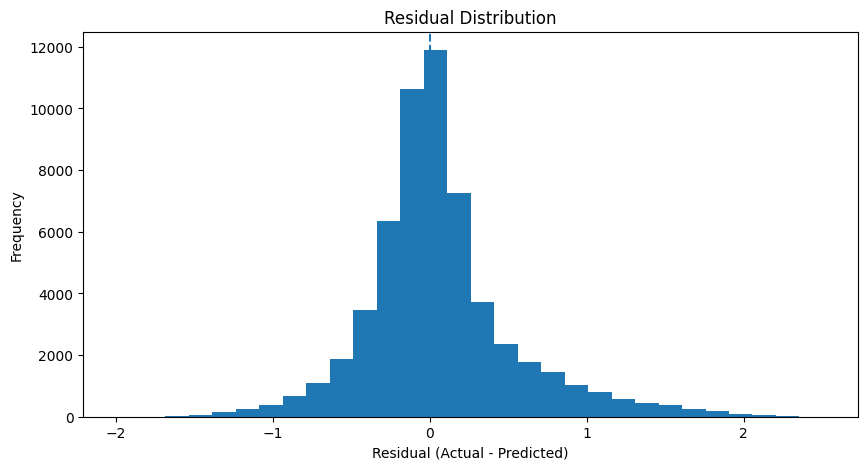

In [27]:
residuals = y_true - y_pred

plt.figure(figsize=(10,5))

plt.hist(residuals, bins=30)
plt.axvline(0, linestyle='--')

plt.title("Residual Distribution")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")

plt.savefig("residual_plot_gru.png", dpi=300)
plt.show()

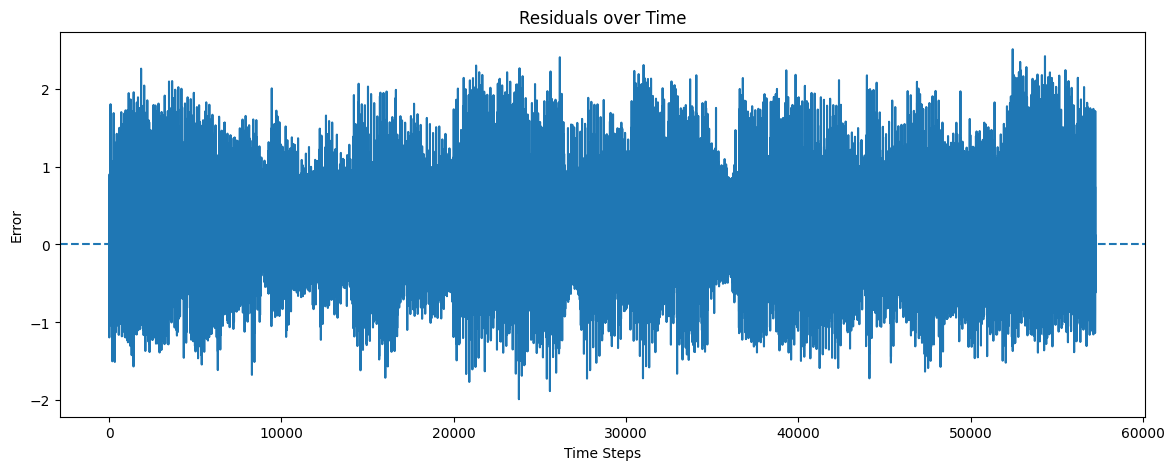

In [28]:
plt.figure(figsize=(14,5))

plt.plot(residuals)

plt.axhline(0, linestyle='--')

plt.title("Residuals over Time")
plt.xlabel("Time Steps")
plt.ylabel("Error")

plt.savefig("residual_time_gru.png", dpi=300)
plt.show()

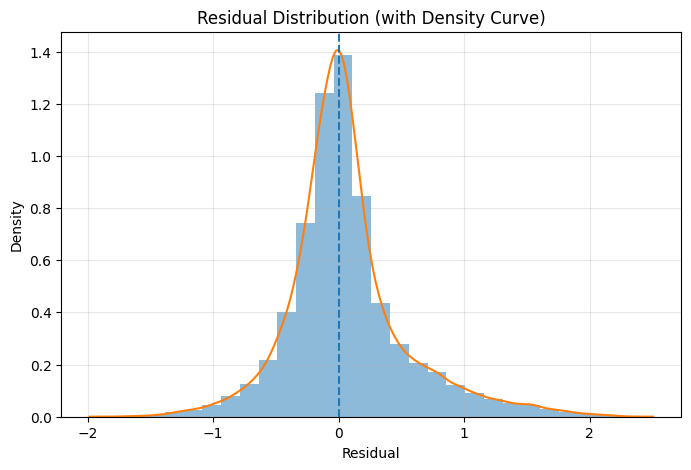

In [29]:
from scipy.stats import gaussian_kde

density = gaussian_kde(residuals)
xs = np.linspace(residuals.min(), residuals.max(), 200)

plt.figure(figsize=(8,5))

plt.hist(residuals, bins=30, density=True, alpha=0.5)
plt.plot(xs, density(xs))

plt.axvline(0, linestyle='--')

plt.title("Residual Distribution (with Density Curve)")
plt.xlabel("Residual")
plt.ylabel("Density")

plt.grid(alpha=0.3)

plt.savefig("residual_distribution_kde_gru.png", dpi=300)
plt.show()

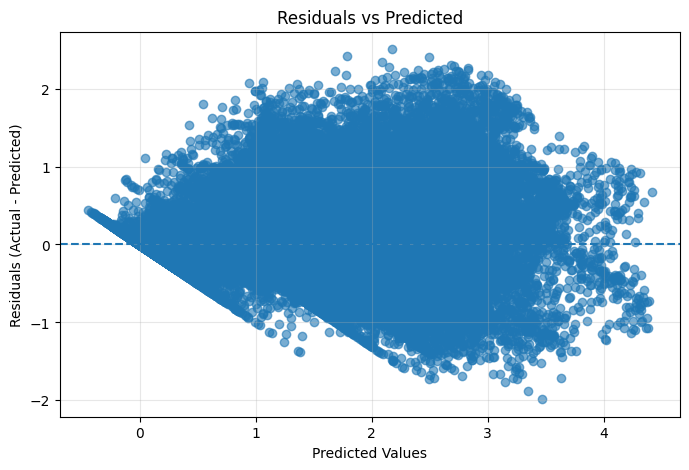

In [30]:
# Convert to numpy
y_true = np.array(actuals).flatten()
y_pred = np.array(preds).flatten()

# Residuals
residuals = y_true - y_pred

plt.figure(figsize=(8,5))

plt.scatter(y_pred, residuals, alpha=0.6)

# Zero error line
plt.axhline(0, linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residuals vs Predicted")

plt.grid(alpha=0.3)

plt.savefig("residual_vs_predicted_gru.png", dpi=300)
plt.show()

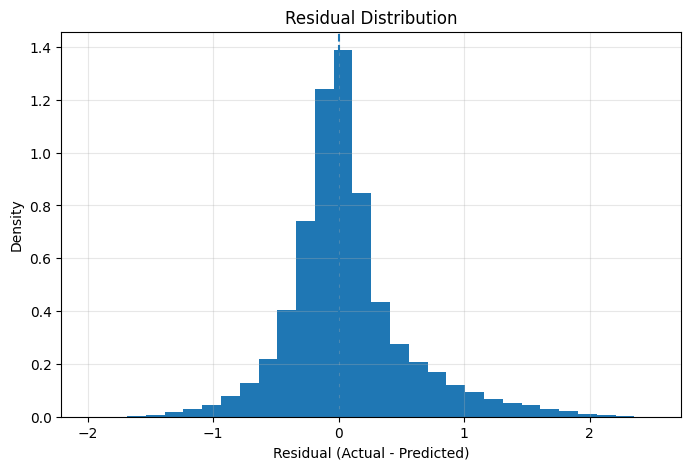

In [31]:
# Convert to numpy
y_true = np.array(actuals).flatten()
y_pred = np.array(preds).flatten()

# Residuals
residuals = y_true - y_pred

plt.figure(figsize=(8,5))

plt.hist(residuals, bins=30, density=True)
plt.axvline(0, linestyle='--')

plt.title("Residual Distribution")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Density")

plt.grid(alpha=0.3)

plt.savefig("residual_distribution_gru.png", dpi=300)
plt.show()

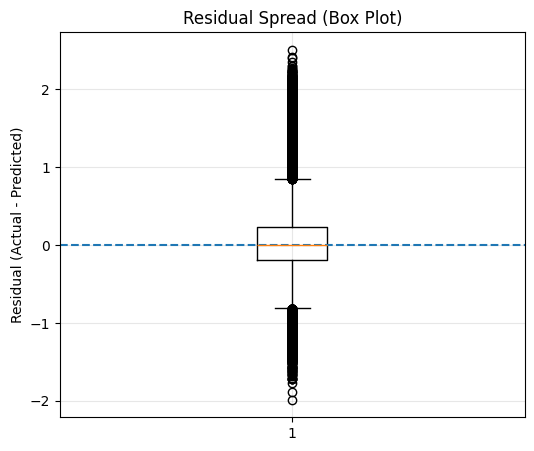

In [32]:
# Convert
y_true = np.array(actuals).flatten()
y_pred = np.array(preds).flatten()

# Residuals
residuals = y_true - y_pred

plt.figure(figsize=(6,5))

plt.boxplot(residuals, vert=True)

# zero reference line
plt.axhline(0, linestyle='--')

plt.title("Residual Spread (Box Plot)")
plt.ylabel("Residual (Actual - Predicted)")

plt.grid(alpha=0.3)

plt.savefig("residual_boxplot_gru.png", dpi=300)
plt.show()

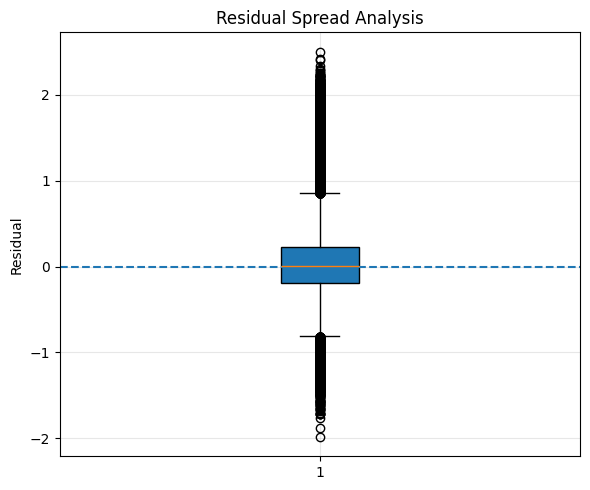

In [33]:
plt.figure(figsize=(6,5))

plt.boxplot(
    residuals,
    vert=True,
    patch_artist=True   # filled box (cleaner look)
)

plt.axhline(0, linestyle='--')

plt.title("Residual Spread Analysis")
plt.ylabel("Residual")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("residual_boxplot_clean_gru.png", dpi=300)
plt.show()

In [34]:
results = pd.DataFrame({
    "actual": actuals,
    "pred": preds
})

results.to_csv(
    "gru_results.csv", index=False)